Доля ложноположительных ошибок (FPR): 0.0498 (Ожидалось: 0.05)


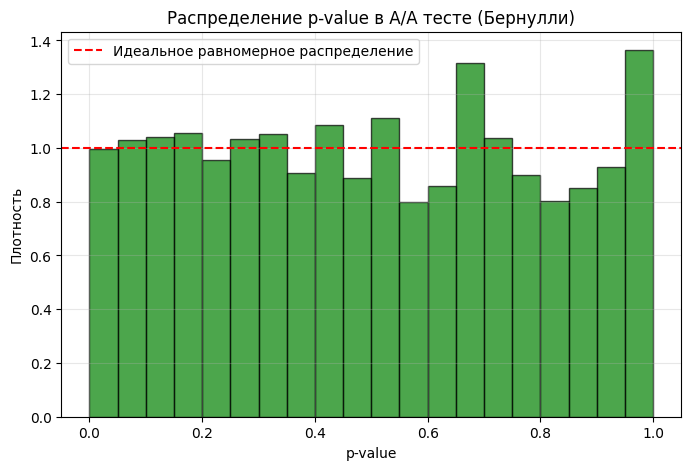

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

def run_aa_simulation(n_simulations=10000, sample_size=1000, p_success=0.2):
    p_values = []
    
    for _ in range(n_simulations):
        # Генерируем две независимые А/А выборки из распределения Бернулли
        # Распределение Бернулли — это биномиальное с n=1
        group_a1 = stats.binom.rvs(n=1, p=p_success, size=sample_size)
        group_a2 = stats.binom.rvs(n=1, p=p_success, size=sample_size)
        
        # Применяем t-критерий Стьюдента (двухвыборочный независимый)
        _, p_val = stats.ttest_ind(group_a1, group_a2, equal_var=True)
        p_values.append(p_val)
        
    return np.array(p_values)

# Запуск симуляции
n_sim = 10000
p_vals = run_aa_simulation(n_simulations=n_sim)

# Расчёт доли ложноположительных ошибок (FPR) при alpha = 0.05
alpha = 0.05
fpr = np.mean(p_vals < alpha)

print(f"Доля ложноположительных ошибок (FPR): {fpr:.4f} (Ожидалось: {alpha})")

# Визуализация распределения p-value
plt.figure(figsize=(8, 5))
plt.hist(p_vals, bins=20, density=True, alpha=0.7, color='g', edgecolor='black')
plt.axhline(y=1.0, color='r', linestyle='--', label='Идеальное равномерное распределение')
plt.title('Распределение p-value в А/А тесте (Бернулли)')
plt.xlabel('p-value')
plt.ylabel('Плотность')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [2]:
import numpy as np
import scipy.stats as stats

def estimate_experiment_power(n_simulations=10000):
    # 1. Задаем исходные параметры из условия задачи
    mu_control = 200        # Среднее время в контроле (сек)
    mu_test = 205           # Среднее время в тесте с учетом ожидаемого эффекта (сек)
    std_dev = 30            # Среднеквадратичное отклонение (шум)
    
    total_users = 1000      # Всего пользователей в неделю
    sample_size = total_users // 2  # Сплитуем поровну на 2 группы (по 500 человек)
    
    alpha = 0.05            # Уровень значимости
    significant_results = 0  # Счётчик успешно обнаруженных эффектов
    
    # Чтобы результаты симуляции были воспроизводимыми
    np.random.seed(42)
    
    # 2. Запускаем цикл многократных симуляций эксперимента
    for _ in range(n_simulations):
        # Генерируем выборки из нормальных распределений для каждой группы
        control_group = np.random.normal(loc=mu_control, scale=std_dev, size=sample_size)
        test_group = np.random.normal(loc=mu_test, scale=std_dev, size=sample_size)
        
        # Применяем двухвыборочный t-критерий Стьюдента для независимых выборок
        _, p_value = stats.ttest_ind(control_group, test_group, equal_var=True)
        
        # Если p-value меньше альфы, значит критерий смог задетектировать эффект
        if p_value < alpha:
            significant_results += 1
            
    # 3. Считаем мощность как процент успешных детекций
    power = (significant_results / n_simulations) * 100
    return power

# Запускаем симуляцию на 10 000 повторений
experiment_power = estimate_experiment_power(n_simulations=10000)
print(f"Ожидаемая мощность эксперимента: {experiment_power:.2f}%")


Ожидаемая мощность эксперимента: 74.93%
